# for picking best health_score and terminal models
## based on amount of advantage accumulated and how in-distribution the policy is

In [20]:
import sys
import os
from pathlib import Path
import importlib
import json

import numpy as np
import matplotlib.pyplot as plt
import torch

# Optional but very useful in notebooks
%load_ext autoreload
%autoreload 2

repo_root = Path("/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl")
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

import src.rl.evaluate_cql_alpha_sweep as eval_cql
import src.rl.evaluate_terminal_reward_models as etm
import src.rl.action_distribution_sweep as action_dist
import src.rl.clinician_baseline as clin_baseline
import src.rl.reward_by_vaso_match as vaso_match
import src.rl.dose_histogram_by_alpha as dose_hist
import src.rl.inspect_fluid_params as raw_params
import src.rl.check_std_floor as std_check
import src.rl.diagnose_fluid_spike as spike_diag
import src.rl.plot_fluid_two_population as fluid_pop
import src.rl.plot_fluid_dose_severity_heatmaps as heatmap_diag


# SAVE_DIR = "/home/jake/Documents/AI_Clinician/models/analysis/cql_alpha_sweep"
# os.makedirs(SAVE_DIR, exist_ok=True)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# get paths to the models

In [21]:
cohort = "picu"
# health_cohort = "sepsis_picu"
health_cohort = "picu" # dynamic deephit trained on all picu patients, not just sepsis patients

if cohort == "picu":    
    if health_cohort == "picu":
        basic_q_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset"
        print(f"Using basic_q_dir: {basic_q_dir}")
        dynamic_deephit_model_dir = "/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/final_model"
        print(f"Using dynamic_deephit_model_dir: {dynamic_deephit_model_dir}")
        cql_model_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset"
        print(f"Using cql_model_dir: {cql_model_dir}")

    elif health_cohort == "sepsis_picu":
        basic_q_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_restricted_dataset"
        print(f"Using basic_q_dir: {basic_q_dir}")
        dynamic_deephit_model_dir = "/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/sepsis_picu/final_model"
        print(f"Using dynamic_deephit_model_dir: {dynamic_deephit_model_dir}")
        cql_model_dir = "/home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_restricted_dataset"
        print(f"Using cql_model_dir: {cql_model_dir}")


Using basic_q_dir: /home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset
Using dynamic_deephit_model_dir: /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/final_model
Using cql_model_dir: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset


# get state dim from the dynamic deephit model

In [22]:
# first, load the dynamic deephit hyperparameters so we can get the state dimension
dynamic_deephit_dir = eval_cql.get_model_dirs(dynamic_deephit_model_dir)[0]
print(f"Dynamic DeepHit model directory: {dynamic_deephit_dir}")
# load results.json from dynamic_deephit_dir
with open(os.path.join(dynamic_deephit_dir, "results.json"), "r") as f:
    dynamic_deephit_results = json.load(f)
state_dim = dynamic_deephit_results['hyperparameters']['d_model']
print(f"State dimension from dynamic deephit hyperparameters: {state_dim}")

No choc directories found in /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/final_model
Found model directory: /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/final_model/unknown_cx3-20-1_20260821-202508_49e52257
Dynamic DeepHit model directory: /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/final_model/unknown_cx3-20-1_20260821-202508_49e52257
State dimension from dynamic deephit hyperparameters: 128


# Load SARSA models x 5 seeds

In [23]:
basic_q_terminal_model_dir = os.path.join(basic_q_dir, "terminal_only")
basic_q_terminal_model_dirs = eval_cql.get_model_dirs(basic_q_terminal_model_dir)

basic_q_terminal_models = []
for model_dir in basic_q_terminal_model_dirs:
    # load terminal sarsa model
    terminal_sarsa_critic, terminal_sarsa_config_manager, terminal_sarsa_hyperparams = etm.load_sarsa_critic(reward_type='terminal', model_dir=model_dir, state_dim=state_dim)
    basic_q_terminal_models.append((terminal_sarsa_critic, terminal_sarsa_config_manager, terminal_sarsa_hyperparams))

Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/terminal_only/choc_basic_q_intake-vis_best_hyperparameters_20260826_163316_with_seeds/unknown_cx3-20-4_20260826-163424_71f56fa6
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/terminal_only/choc_basic_q_intake-vis_best_hyperparameters_20260826_163316_with_seeds/unknown_cx3-20-4_20260826-165417_d7c6986a
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/terminal_only/choc_basic_q_intake-vis_best_hyperparameters_20260826_163316_with_seeds/unknown_cx3-20-4_20260826-171719_bd2e5ef8
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_fr

In [24]:
basic_q_health_score_model_dir = os.path.join(basic_q_dir, "health_score_change_only")
basic_q_health_score_model_dirs = etm.get_model_dirs(basic_q_health_score_model_dir)

basic_q_health_score_models = []
for model_dir in basic_q_health_score_model_dirs:
    # load health score sarsa model
    health_score_sarsa_critic, health_score_sarsa_config_manager, health_score_sarsa_hyperparams = etm.load_sarsa_critic(reward_type='health_score', model_dir=model_dir, state_dim=state_dim)
    basic_q_health_score_models.append((health_score_sarsa_critic, health_score_sarsa_config_manager, health_score_sarsa_hyperparams))

Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/choc_basic_q_intake-vis_best_hyperparameters_20260826_163652_with_seeds/unknown_cx3-20-4_20260826-172402_1ce5be77
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/choc_basic_q_intake-vis_best_hyperparameters_20260826_163652_with_seeds/unknown_cx3-20-4_20260826-165737_72aa451a
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/choc_basic_q_intake-vis_best_hyperparameters_20260826_163652_with_seeds/unknown_cx3-20-4_20260826-174709_9876cf65
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/basic_q/split_0/sepsis/intake-

# Load CQL models

In [25]:
cql_terminal_model_dir = os.path.join(cql_model_dir, "terminal_only", "cql_alpha_sweep")
cql_terminal_model_dirs = eval_cql.get_model_dirs(cql_terminal_model_dir)

cql_terminal_models = []
for model_dir in cql_terminal_model_dirs:
    # load terminal sarsa model
    terminal_actor, terminal_critic, terminal_config_manager, terminal_hyperparams = \
        etm.load_actor_and_critic(
            model_dir=model_dir, model_type = 'cql', state_dim=state_dim,
        )
    cql_terminal_models.append((terminal_actor, terminal_critic, terminal_config_manager, terminal_hyperparams))

Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/terminal_only/cql_alpha_sweep/choc_cql_with_logprobs_intake-vis_single_hyperparameter_sweep_20260908_143535/unknown_cx3-20-1_20260908-154520_3b193fea
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/terminal_only/cql_alpha_sweep/choc_cql_with_logprobs_intake-vis_single_hyperparameter_sweep_20260908_143535/unknown_cx3-20-1_20260908-153354_880a8738
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/terminal_only/cql_alpha_sweep/choc_cql_with_logprobs_intake-vis_single_hyperparameter_sweep_20260908_143535/unknown_cx3-20-1_20260908-144834_f231bfde
Found model directory: /home/jake/Documents/AI

In [26]:
cql_health_score_model_dir = os.path.join(cql_model_dir, "health_score_change_only", "cql_alpha_sweep")
cql_health_score_model_dirs = eval_cql.get_model_dirs(cql_health_score_model_dir)

cql_health_score_models = []
for model_dir in cql_health_score_model_dirs:
    # load health score model
    health_score_actor, health_score_critic, health_score_config_manager, health_score_hyperparams = \
        etm.load_actor_and_critic(
            model_dir=model_dir, model_type = 'cql', state_dim=state_dim,
        )
    cql_health_score_models.append((health_score_actor, health_score_critic, health_score_config_manager, health_score_hyperparams))

Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/cql_alpha_sweep/choc_cql_with_logprobs_intake-vis_single_hyperparameter_sweep_20260908_160551/unknown_cx3-20-1_20260908-174119_68357e0f
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/cql_alpha_sweep/choc_cql_with_logprobs_intake-vis_single_hyperparameter_sweep_20260908_160551/unknown_cx3-20-1_20260908-182706_c4213796
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/cql_alpha_sweep/choc_cql_with_logprobs_intake-vis_single_hyperparameter_sweep_20260908_160551/unknown_cx3-20-1_20260908-180416_6ce7b233
Found model d

# Load data

In [27]:
health_score_config_manager.data_config['unit_stay_ids_path'] = os.path.join(
    health_score_config_manager.get_data_dir, 'cohorts',
    'icu_units',
    f"{health_score_config_manager.unit.lower()}_stay_ids.csv"
)

health_score_config_manager.data_config['age_stay_ids_path'] = os.path.join(
    health_score_config_manager.get_data_dir, 'cohorts',
    'age', 'pediatric_stay_ids.csv'
)

In [28]:
processors = {}
processors['train'], processors['val'], processors['test'] = etm.load_data(health_score_config_manager, health_score_hyperparams)  

using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type
using shifted actions for RL dataset
Using health_score reward type


In [29]:
# real clinician non-zero fluid doses, from training data
fluid_doses = processors['train'].rl_dataset["actions"][:, 0]
nonzero_fluid = fluid_doses[fluid_doses > 1e-4]

# clamp to avoid inf at exact 0/1 boundaries, then invert the sigmoid (logit)
nonzero_fluid_clamped = nonzero_fluid.clamp(1e-4, 1 - 1e-4)
raw_fluid = torch.logit(nonzero_fluid_clamped)

print(f"Fluid: dose-space std={nonzero_fluid.std():.4f}, "
      f"raw-space std={raw_fluid.std():.4f}, raw-space mean={raw_fluid.mean():.4f}")

# same for vaso
vaso_doses = processors['train'].rl_dataset["actions"][:, 1]
nonzero_vaso = vaso_doses[vaso_doses > 1e-4]
nonzero_vaso_clamped = nonzero_vaso.clamp(1e-4, 1 - 1e-4)
raw_vaso = torch.logit(nonzero_vaso_clamped)

print(f"Vaso: dose-space std={nonzero_vaso.std():.4f}, "
      f"raw-space std={raw_vaso.std():.4f}, raw-space mean={raw_vaso.mean():.4f}")

Fluid: dose-space std=0.1420, raw-space std=0.6721, raw-space mean=0.1841
Vaso: dose-space std=0.1158, raw-space std=0.6342, raw-space mean=-1.0675


In [30]:
actions = processors['train'].rl_dataset['actions']

fluids = actions[:, 0]
vasopressors = actions[:, 1] 

# get min non-zero fluid and vasopressor doses
min_nonzero_fluid = fluids[fluids > 0].min()
min_nonzero_vasopressor = vasopressors[vasopressors > 0].min()

print(f"Min non-zero fluid dose: {min_nonzero_fluid}")
print(f"Min non-zero vasopressor dose: {min_nonzero_vasopressor}")

Min non-zero fluid dose: 0.0001319456350756809
Min non-zero vasopressor dose: 0.006044956389814615


# clinician baseline

In [31]:
clinician_baseline_val = clin_baseline.compute_clinician_baseline(processors['val'].rl_dataset["actions"])
clin_baseline.print_clinician_baseline(clinician_baseline_val, label="val")

=== Clinician baseline (val) ===
  fluid: rate=90.9%, mean=0.4958, nonzero_mean=0.5456
  vaso: rate=8.3%, mean=0.0213, nonzero_mean=0.2569


In [32]:
clinician_baseline_test = clin_baseline.compute_clinician_baseline(processors['test'].rl_dataset["actions"])
clin_baseline.print_clinician_baseline(clinician_baseline_test, label="test")

=== Clinician baseline (test) ===
  fluid: rate=90.5%, mean=0.4900, nonzero_mean=0.5415
  vaso: rate=9.4%, mean=0.0260, nonzero_mean=0.2775


## health_score

In [33]:
training_health_score = processors['train'].dynamic_deephit_predictions["health_score"]
# remove values at indices processors['train'].dynamic_deephit_predictions['index_ptr'][1:] - 1
indices_to_remove = processors['train'].dynamic_deephit_predictions['index_ptr'][1:] - 1
training_health_score = np.delete(training_health_score, indices_to_remove)

val_health_score = processors['val'].dynamic_deephit_predictions["health_score"]
# remove values at indices processors['val'].dynamic_deephit_predictions['index_ptr'][1:] - 1
indices_to_remove = processors['val'].dynamic_deephit_predictions['index_ptr'][1:] - 1
val_health_score = np.delete(val_health_score, indices_to_remove)

test_health_score = processors['test'].dynamic_deephit_predictions["health_score"]
# remove values at indices processors['test'].dynamic_deephit_predictions['index_ptr'][1:] - 1
indices_to_remove = processors['test'].dynamic_deephit_predictions['index_ptr'][1:] - 1
test_health_score = np.delete(test_health_score, indices_to_remove)

training_actions = processors['train'].rl_dataset["actions"]

# Calculate advantage

In [34]:
# Build alpha -> model dicts for each CQL sweep, keyed by each model's own cql_alpha hyperparameter.
# CQL tuples are (actor, critic, config_manager, hyperparams) -> hyperparams at index 3
cql_health_score_by_alpha = {m[3]['cql_alpha']: m for m in cql_health_score_models}
cql_terminal_by_alpha = {m[3]['cql_alpha']: m for m in cql_terminal_models}

print("Health-score alphas found:", sorted(cql_health_score_by_alpha.keys()))
print("Terminal alphas found:", sorted(cql_terminal_by_alpha.keys()))

Health-score alphas found: [0.0, 0.0001, 0.0005, 0.00075, 0.001, 0.002, 0.003, 0.004, 0.005, 0.006, 0.007, 0.008, 0.009, 0.01, 0.025, 0.05, 0.1, 0.5]
Terminal alphas found: [0.0, 0.0001, 0.0005, 0.00075, 0.001, 0.002, 0.003, 0.004, 0.005, 0.006, 0.007, 0.008, 0.009, 0.01, 0.025, 0.05, 0.1, 0.5]


=== alpha=0.0 ===


    own-critic Q IQR (real clinician actions): 0.9824
    SARSA seed 1 Q IQR (real clinician actions): 0.9660
    SARSA seed 2 Q IQR (real clinician actions): 0.9962
    SARSA seed 3 Q IQR (real clinician actions): 0.9462
    SARSA seed 4 Q IQR (real clinician actions): 1.0221
    SARSA seed 5 Q IQR (real clinician actions): 1.0000
  own-critic advantage:   raw=0.0395, normalized=0.0402
  SARSA-critic advantage: raw mean=0.0805, normalized mean=0.0817 (normalized per-seed=[0.0827 0.083  0.0831 0.0813 0.0783])
  occupancy support of chosen actions: 84.5%
  done in 5.7s

=== alpha=0.0001 ===
    own-critic Q IQR (real clinician actions): 0.9780
    SARSA seed 1 Q IQR (real clinician actions): 0.9660
    SARSA seed 2 Q IQR (real clinician actions): 0.9962
    SARSA seed 3 Q IQR (real clinician actions): 0.9462
    SARSA seed 4 Q IQR (real clinician actions): 1.0221
    SARSA seed 5 Q IQR (real clinician actions): 1.0000
  own-critic advantage:   raw=0.0369, normalized=0.0377
  SARSA-criti

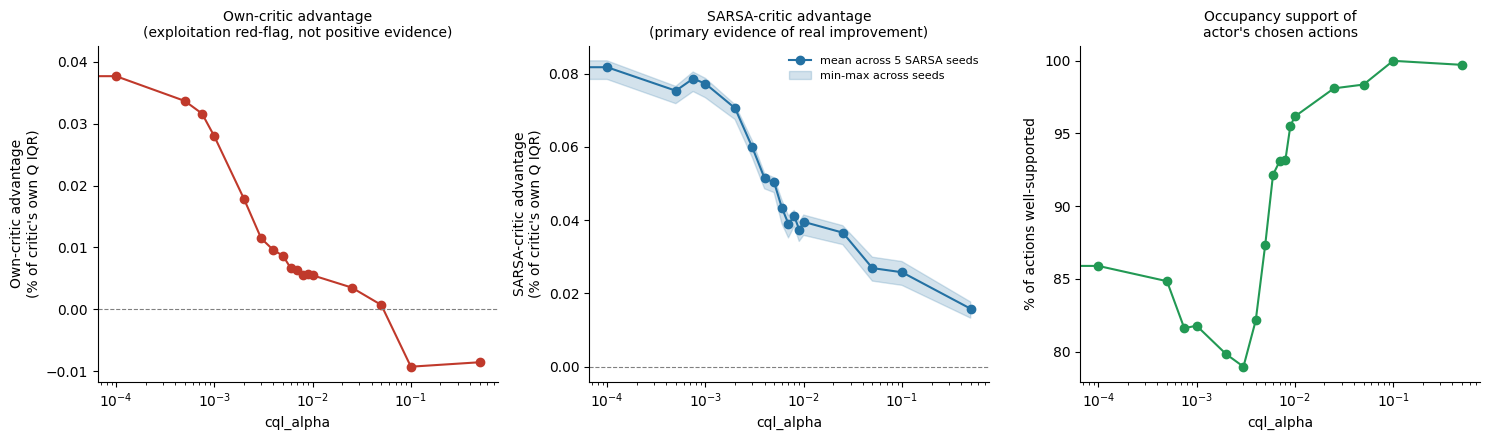

In [35]:
save_path = os.path.join(cql_model_dir, "cql_alpha_sweep_health_score_n_severity_bins_100.png")    


# --- Health-score reward: CQL alpha sweep vs. all 5 health-score SARSA seeds ---
results_health_score, fig_health_score = eval_cql.run_alpha_sweep_analysis(
    cql_health_score_by_alpha,
    processors['val'],
    basic_q_health_score_models,   # the 5 health-score SARSA seeds, as independent judges
    val_health_score,
    training_actions,
    training_health_score,
    n_severity_bins = 200,
    save_path=save_path,
)

In [36]:
model_entry_zero = cql_health_score_by_alpha[0]  # or whatever key represents your lowest alpha
actions_zero = action_dist.get_actor_actions(model_entry_zero, processors['val'])
stats_zero = action_dist.compute_action_distribution_stats(actions_zero)
print(stats_zero)

{'fluid_fire_rate': 0.1963128937793948, 'fluid_mean_dose': 0.18657322, 'fluid_mean_nonzero_dose': 0.950387, 'vaso_fire_rate': 0.0, 'vaso_mean_dose': 0.0, 'vaso_mean_nonzero_dose': nan}


Note: alpha=0 excluded from plot (log scale can't show it).
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/cql_alpha_sweep_combined_health_score_n_severity_bins_100.png


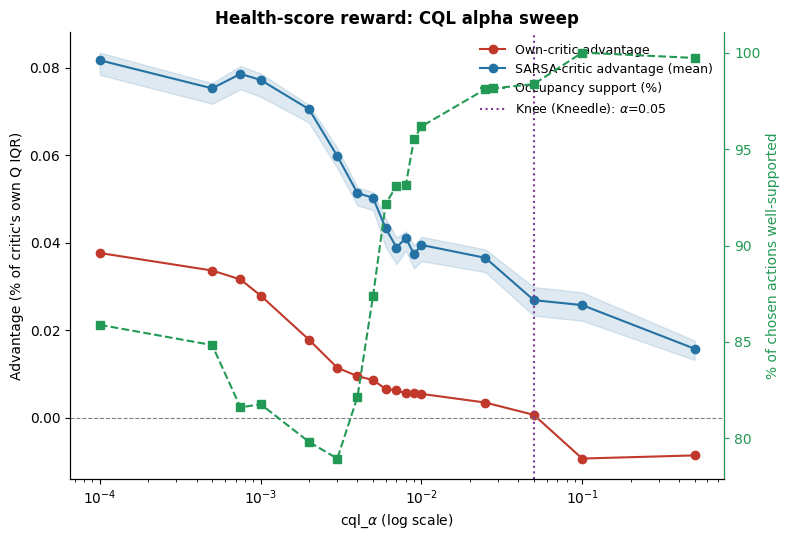

In [37]:
save_path = os.path.join(cql_model_dir, "cql_alpha_sweep_combined_health_score_n_severity_bins_100.png")  

fig = eval_cql.plot_combined_alpha_sweep(
    results_health_score,
    normalized=True, log_scale=True,
    title="Health-score reward: CQL alpha sweep",
    save_path=save_path,
)

Ref: Satopaa, V., Albrecht, J., Irwin, D., & Barker, B. (2011). "Finding a 'kneedle' in a haystack: Detecting knee points in system behavior." 31st International Conference on Distributed Computing Systems Workshops.

We selected cql_alpha by identifying the knee of the SARSA-critic
advantage curve as a function of alpha, using the Kneedle
algorithm~\cite{satopaa2011kneedle} (curve="convex", direction="decreasing"),
yielding alpha=0.006. As a corroborating check, we separately identified
the knee of the occupancy-support curve (curve="concave",
direction="increasing", restricted to alpha >= 0.003 to exclude a small,
likely noise-driven non-monotonicity at the lowest tested values), which
independently converged on the same value (alpha=0.006).

In [38]:
knee_advantage = eval_cql.find_knee_alpha(results_health_score, metric="sarsa_advantage", curve="convex", direction="decreasing")
knee_occupancy = eval_cql.find_knee_alpha(
    results_health_score, metric="occupancy", curve="concave", direction="increasing",
    alpha_min=0.003,  # restrict to the genuinely-increasing region, past the early noisy dip
)
print(f"Advantage knee: {knee_advantage}, Occupancy knee: {knee_occupancy}")

Advantage knee: 0.05, Occupancy knee: 0.025


=== Fluid dose distribution summary (nonzero doses only) ===
  Clinician (real): n=81927, mean=0.5456, std=0.1377, median=0.5590, p10=0.3764, p25=0.4902, p75=0.6252, p90=0.7001
  alpha=0.01: n=90056, mean=0.4541, std=0.2149, median=0.4590, p10=0.1554, p25=0.3281, p75=0.5642, p90=0.7255
  alpha=0.025: n=90152, mean=0.4911, std=0.1865, median=0.4903, p10=0.2621, p25=0.3931, p75=0.6010, p90=0.7208
  alpha=0.05: n=90032, mean=0.5230, std=0.1551, median=0.5261, p10=0.3736, p25=0.4684, p75=0.6058, p90=0.6806
  alpha=0.1: n=89944, mean=0.5451, std=0.1522, median=0.5668, p10=0.4186, p25=0.4873, p75=0.6536, p90=0.6889
  alpha=0.5: n=90044, mean=0.5006, std=0.1729, median=0.5449, p10=0.2484, p25=0.4435, p75=0.6242, p90=0.6625
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/dose_histogram_fluid_by_alpha.png


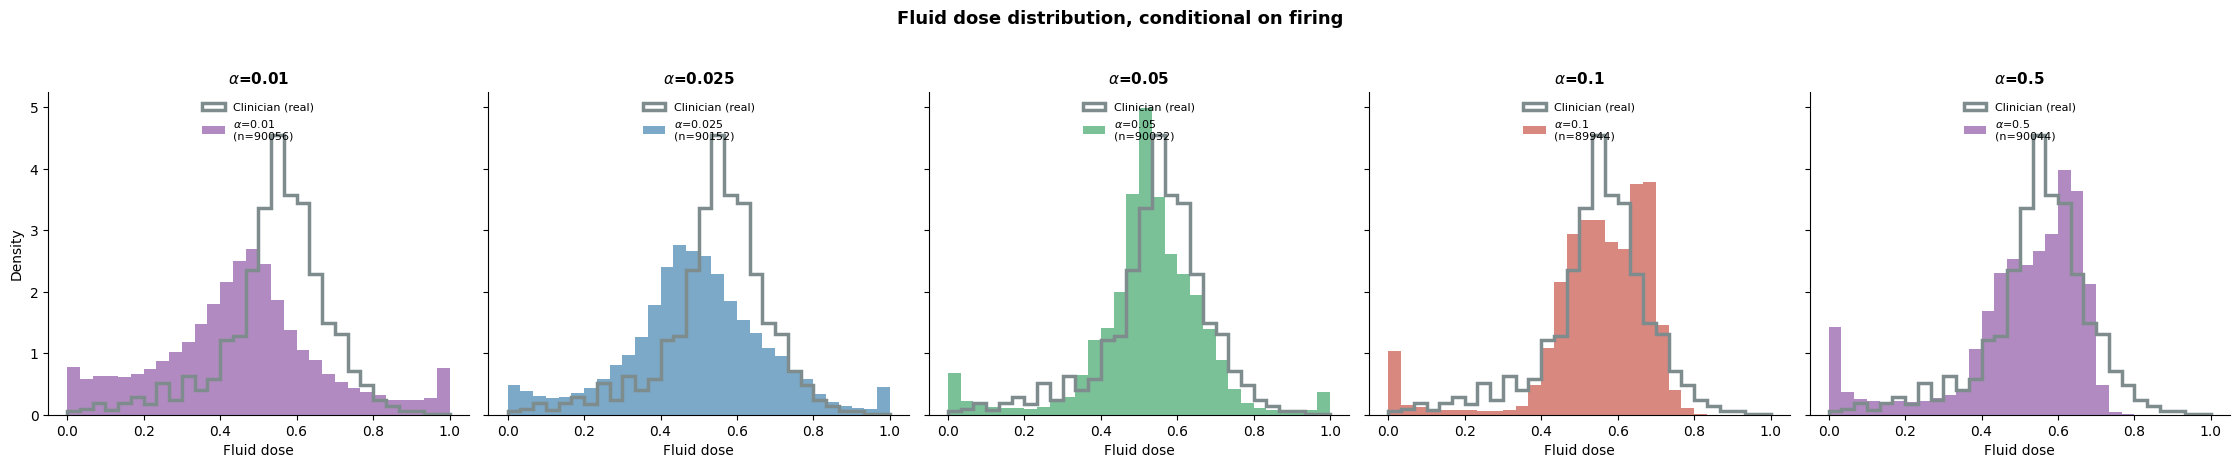

In [40]:
clinician_actions_val = processors['val'].rl_dataset["actions"]

fig = dose_hist.plot_dose_histograms(
    cql_health_score_by_alpha,
    alphas_to_show=[0.01, 0.025, 0.05, 0.1, 0.5],
    processor=processors['val'],
    clinician_actions=clinician_actions_val,
    dim=0, dim_name="Fluid",
    get_actor_actions_fn=action_dist.get_actor_actions,
    save_path=os.path.join(cql_model_dir, "dose_histogram_fluid_by_alpha.png"),
)

=== Fluid dose distribution summary (nonzero doses only) ===
  Clinician (real): n=81927, mean=0.5456, std=0.1377, median=0.5590, p10=0.3764, p25=0.4902, p75=0.6252, p90=0.7001
  alpha=0.0: n=17698, mean=0.9504, std=0.1726, median=1.0000, p10=0.9342, p25=0.9999, p75=1.0000, p90=1.0000
  alpha=0.0001: n=19199, mean=0.8187, std=0.3452, median=1.0000, p10=0.0641, p25=0.9192, p75=1.0000, p90=1.0000
  alpha=0.003: n=69829, mean=0.5930, std=0.3281, median=0.5576, p10=0.1275, p25=0.3148, p75=0.9824, p90=0.9998
  alpha=0.006: n=87613, mean=0.4387, std=0.2578, median=0.4124, p10=0.1151, p25=0.2485, p75=0.5667, p90=0.8692
  alpha=0.01: n=90056, mean=0.4541, std=0.2149, median=0.4590, p10=0.1554, p25=0.3281, p75=0.5642, p90=0.7255
  alpha=0.1: n=89944, mean=0.5451, std=0.1522, median=0.5668, p10=0.4186, p25=0.4873, p75=0.6536, p90=0.6889
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/dose_hi

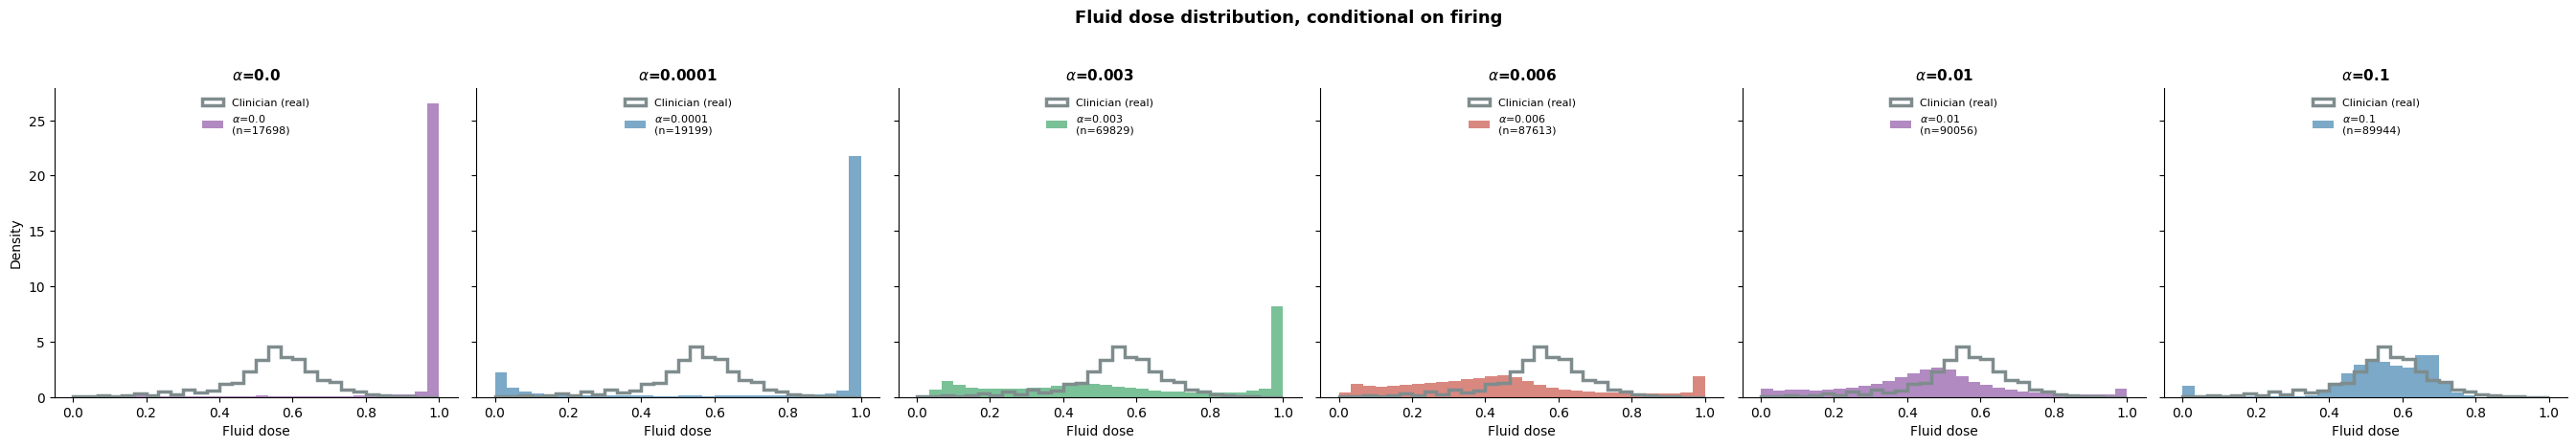

In [41]:
clinician_actions_val = processors['val'].rl_dataset["actions"]

fig = dose_hist.plot_dose_histograms(
    cql_health_score_by_alpha,
    alphas_to_show=[0., 0.0001, 0.003, 0.006, 0.01, 0.1],
    processor=processors['val'],
    clinician_actions=clinician_actions_val,
    dim=0, dim_name="Fluid",
    get_actor_actions_fn=action_dist.get_actor_actions,
    save_path=os.path.join(cql_model_dir, "dose_histogram_fluid_by_alpha.png"),
)

=== f_raw_mean / f_std summary across alpha ===
  alpha=0.0001: f_raw_mean [mean=-6.242, std=7.796, min=-12.182, max=13.788, p10=-11.234, p90=10.715]  f_std [mean=0.135, min=0.135, max=0.179]
  alpha=0.003: f_raw_mean [mean=0.455, std=4.533, min=-9.230, max=17.542, p10=-4.535, p90=7.910]  f_std [mean=0.135, min=0.135, max=0.135]
  alpha=0.006: f_raw_mean [mean=-0.196, std=2.179, min=-5.818, max=14.817, p10=-2.351, p90=1.812]  f_std [mean=0.135, min=0.135, max=0.135]
  alpha=0.01: f_raw_mean [mean=-0.208, std=1.476, min=-6.791, max=12.236, p10=-1.705, p90=0.970]  f_std [mean=0.135, min=0.135, max=0.135]
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/fluid_raw_params_by_alpha.png


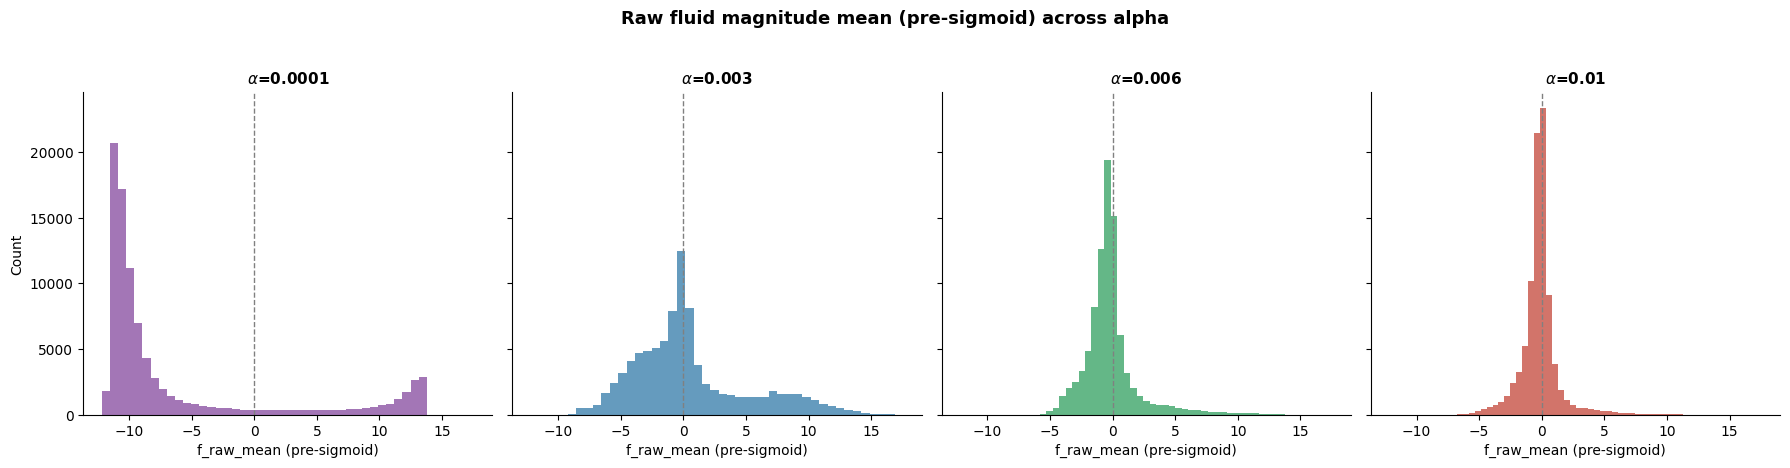

In [19]:
fig = raw_params.plot_raw_params_by_alpha(
    cql_health_score_by_alpha,
    alphas_to_show=[0.0001, 0.003, 0.006, 0.01],
    processor=processors['val'],
    save_path=os.path.join(cql_model_dir, "fluid_raw_params_by_alpha.png"),
)

# model fixes to prevent std from reachign floor

In [23]:
cql_health_score_fixed_alpha_model_dir = os.path.join(cql_model_dir, "health_score_change_only", "fixed_alpha_std_fix")
cql_health_score_fixed_alpha_model_dirs = eval_cql.get_model_dirs(cql_health_score_fixed_alpha_model_dir)

cql_health_score_fixed_alpha_models = []
for model_dir in cql_health_score_fixed_alpha_model_dirs:
    # load health score sarsa model
    health_score_actor, health_score_critic, health_score_config_manager, health_score_hyperparams = \
        etm.load_actor_and_critic(
            model_dir=model_dir, model_type = 'cql', state_dim=state_dim,
        )
    cql_health_score_fixed_alpha_models.append((health_score_actor, health_score_critic, health_score_config_manager, health_score_hyperparams))

Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha_std_fix/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260910_113911/local_2726772d
Loading config manager from: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha_std_fix/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260910_113911/local_2726772d/config_manager.pkl
config_manager.pkl not found in /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha_std_fix/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260910_113911/local_2726772d, checking parent dire

In [25]:
# Build alpha -> model dicts for each CQL sweep, keyed by each model's own cql_alpha hyperparameter.
# CQL tuples are (actor, critic, config_manager, hyperparams) -> hyperparams at index 3
cql_health_score_by_alpha = {m[3]['cql_alpha']: m for m in cql_health_score_fixed_alpha_models}

print("Health-score alphas found:", sorted(cql_health_score_by_alpha.keys()))


Health-score alphas found: [0.006]


=== Fluid dose distribution summary (nonzero doses only) ===
  Clinician (real): n=81927, mean=0.5456, std=0.1377, median=0.5590, p10=0.3764, p25=0.4902, p75=0.6252, p90=0.7001
  alpha=0.006: n=85555, mean=0.5075, std=0.3006, median=0.4751, p10=0.0805, p25=0.3041, p75=0.7042, p90=0.9995
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/dose_histogram_fluid_by_alpha.png


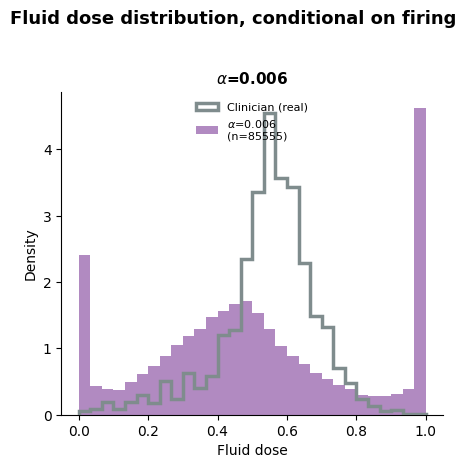

In [28]:
clinician_actions_val = processors['val'].rl_dataset["actions"]

fig = dose_hist.plot_dose_histograms(
    cql_health_score_by_alpha,
    alphas_to_show=[0.006],
    processor=processors['val'],
    clinician_actions=clinician_actions_val,
    dim=0, dim_name="Fluid",
    get_actor_actions_fn=action_dist.get_actor_actions,
    save_path=os.path.join(cql_model_dir, "dose_histogram_fluid_by_alpha.png"),
)

=== f_raw_mean / f_std summary across alpha ===
  alpha=0.006: f_raw_mean [mean=0.307, std=5.695, min=-21.048, max=24.240, p10=-5.216, p90=7.144]  f_std [mean=0.957, min=0.190, max=2.718]
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/fluid_raw_params_by_alpha.png


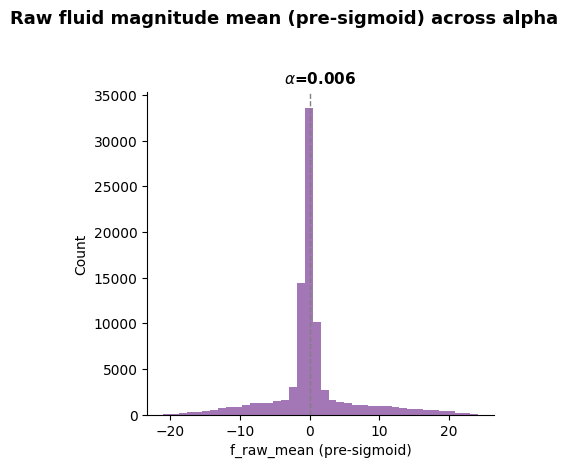

In [27]:
fig = raw_params.plot_raw_params_by_alpha(
    cql_health_score_by_alpha,
    alphas_to_show=[0.006],
    processor=processors['val'],
    save_path=os.path.join(cql_model_dir, "fluid_raw_params_by_alpha.png"),
)

Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha_std_fix2/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260910_132727/local_a79ed2a4
Loading config manager from: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha_std_fix2/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260910_132727/local_a79ed2a4/config_manager.pkl
config_manager.pkl not found in /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha_std_fix2/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260910_132727/local_a79ed2a4, checking parent d

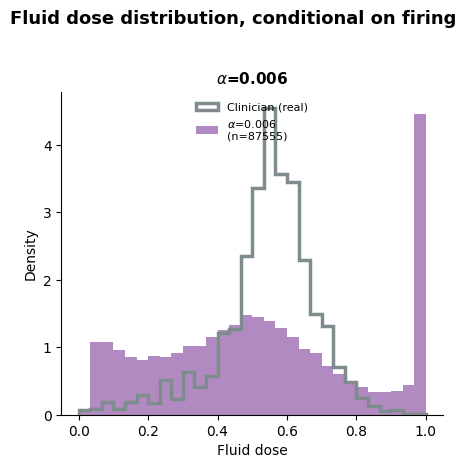

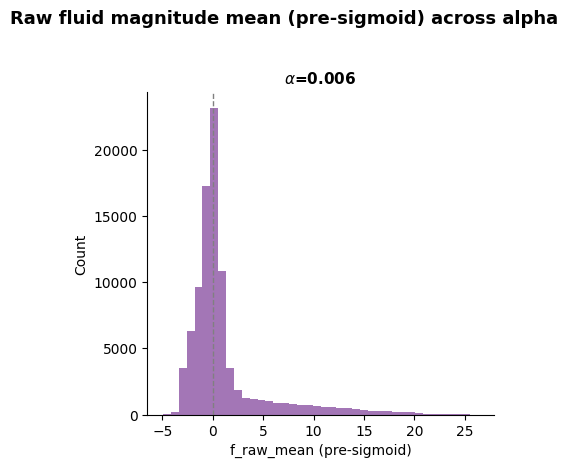

In [14]:
cql_health_score_fixed_alpha_model_dir = os.path.join(cql_model_dir, "health_score_change_only", "fixed_alpha_std_fix2")
cql_health_score_fixed_alpha_model_dirs = eval_cql.get_model_dirs(cql_health_score_fixed_alpha_model_dir)

cql_health_score_fixed_alpha_models = []
for model_dir in cql_health_score_fixed_alpha_model_dirs:
    # load health score sarsa model
    health_score_actor, health_score_critic, health_score_config_manager, health_score_hyperparams = \
        etm.load_actor_and_critic(
            model_dir=model_dir, model_type = 'cql', state_dim=state_dim,
        )
    cql_health_score_fixed_alpha_models.append((health_score_actor, health_score_critic, health_score_config_manager, health_score_hyperparams))

# Build alpha -> model dicts for each CQL sweep, keyed by each model's own cql_alpha hyperparameter.
# CQL tuples are (actor, critic, config_manager, hyperparams) -> hyperparams at index 3
cql_health_score_by_alpha = {m[3]['cql_alpha']: m for m in cql_health_score_fixed_alpha_models}

print("Health-score alphas found:", sorted(cql_health_score_by_alpha.keys()))

clinician_actions_val = processors['val'].rl_dataset["actions"]

fig = dose_hist.plot_dose_histograms(
    cql_health_score_by_alpha,
    alphas_to_show=[0.006],
    processor=processors['val'],
    clinician_actions=clinician_actions_val,
    dim=0, dim_name="Fluid",
    get_actor_actions_fn=action_dist.get_actor_actions,
    save_path=os.path.join(cql_model_dir, "dose_histogram_fluid_by_alpha.png"),
)

fig = raw_params.plot_raw_params_by_alpha(
    cql_health_score_by_alpha,
    alphas_to_show=[0.006],
    processor=processors['val'],
    save_path=os.path.join(cql_model_dir, "fluid_raw_params_by_alpha.png"),
)

Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha_std_fix3/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260910_144214/local_f6df6372
Loading config manager from: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha_std_fix3/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260910_144214/local_f6df6372/config_manager.pkl
config_manager.pkl not found in /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha_std_fix3/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260910_144214/local_f6df6372, checking parent d

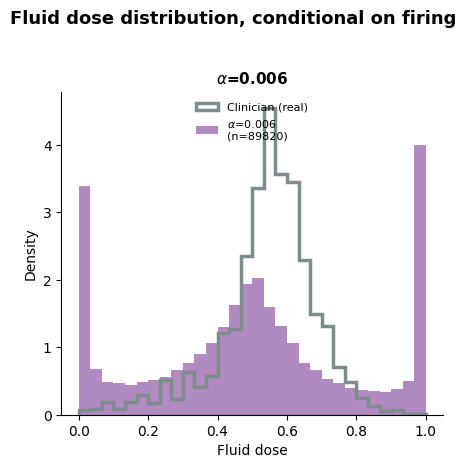

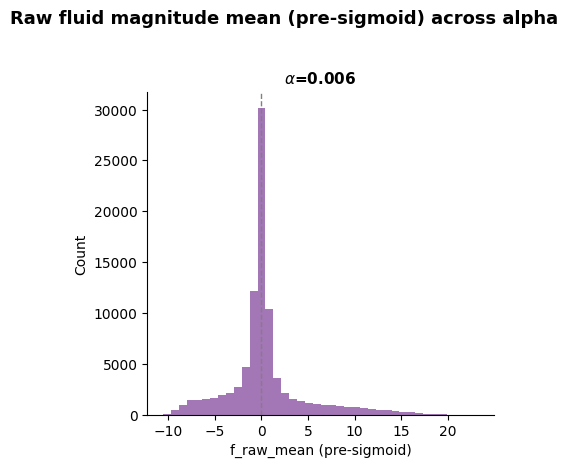

In [16]:
cql_health_score_fixed_alpha_model_dir = os.path.join(cql_model_dir, "health_score_change_only", "fixed_alpha_std_fix3")
cql_health_score_fixed_alpha_model_dirs = eval_cql.get_model_dirs(cql_health_score_fixed_alpha_model_dir)

cql_health_score_fixed_alpha_models = []
for model_dir in cql_health_score_fixed_alpha_model_dirs:
    # load health score sarsa model
    health_score_actor, health_score_critic, health_score_config_manager, health_score_hyperparams = \
        etm.load_actor_and_critic(
            model_dir=model_dir, model_type = 'cql', state_dim=state_dim,
        )
    cql_health_score_fixed_alpha_models.append((health_score_actor, health_score_critic, health_score_config_manager, health_score_hyperparams))

# Build alpha -> model dicts for each CQL sweep, keyed by each model's own cql_alpha hyperparameter.
# CQL tuples are (actor, critic, config_manager, hyperparams) -> hyperparams at index 3
cql_health_score_by_alpha = {m[3]['cql_alpha']: m for m in cql_health_score_fixed_alpha_models}

print("Health-score alphas found:", sorted(cql_health_score_by_alpha.keys()))

clinician_actions_val = processors['val'].rl_dataset["actions"]

fig = dose_hist.plot_dose_histograms(
    cql_health_score_by_alpha,
    alphas_to_show=[0.006],
    processor=processors['val'],
    clinician_actions=clinician_actions_val,
    dim=0, dim_name="Fluid",
    get_actor_actions_fn=action_dist.get_actor_actions,
    save_path=os.path.join(cql_model_dir, "dose_histogram_fluid_by_alpha.png"),
)

fig = raw_params.plot_raw_params_by_alpha(
    cql_health_score_by_alpha,
    alphas_to_show=[0.006],
    processor=processors['val'],
    save_path=os.path.join(cql_model_dir, "fluid_raw_params_by_alpha.png"),
)

Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha_std_fix4/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260910_155019/local_82fc2edf
Loading config manager from: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha_std_fix4/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260910_155019/local_82fc2edf/config_manager.pkl
config_manager.pkl not found in /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha_std_fix4/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260910_155019/local_82fc2edf, checking parent d

RuntimeError: Unexpected error from cudaGetDeviceCount(). Did you run some cuda functions before calling NumCudaDevices() that might have already set an error? Error 804: forward compatibility was attempted on non supported HW

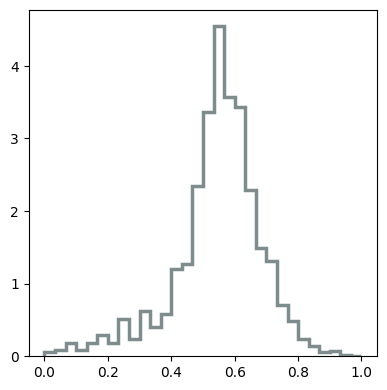

In [14]:
cql_health_score_fixed_alpha_model_dir = os.path.join(cql_model_dir, "health_score_change_only", "fixed_alpha_std_fix4")
cql_health_score_fixed_alpha_model_dirs = eval_cql.get_model_dirs(cql_health_score_fixed_alpha_model_dir)

cql_health_score_fixed_alpha_models = []
for model_dir in cql_health_score_fixed_alpha_model_dirs:
    # load health score sarsa model
    health_score_actor, health_score_critic, health_score_config_manager, health_score_hyperparams = \
        etm.load_actor_and_critic(
            model_dir=model_dir, model_type = 'cql', state_dim=state_dim,
        )
    cql_health_score_fixed_alpha_models.append((health_score_actor, health_score_critic, health_score_config_manager, health_score_hyperparams))

# Build alpha -> model dicts for each CQL sweep, keyed by each model's own cql_alpha hyperparameter.
# CQL tuples are (actor, critic, config_manager, hyperparams) -> hyperparams at index 3
cql_health_score_by_alpha = {m[3]['cql_alpha']: m for m in cql_health_score_fixed_alpha_models}

print("Health-score alphas found:", sorted(cql_health_score_by_alpha.keys()))

clinician_actions_val = processors['val'].rl_dataset["actions"]

fig = dose_hist.plot_dose_histograms(
    cql_health_score_by_alpha,
    alphas_to_show=[0.006],
    processor=processors['val'],
    clinician_actions=clinician_actions_val,
    dim=0, dim_name="Fluid",
    get_actor_actions_fn=action_dist.get_actor_actions,
    save_path=os.path.join(cql_model_dir, "dose_histogram_fluid_by_alpha.png"),
)

fig = raw_params.plot_raw_params_by_alpha(
    cql_health_score_by_alpha,
    alphas_to_show=[0.006],
    processor=processors['val'],
    save_path=os.path.join(cql_model_dir, "fluid_raw_params_by_alpha.png"),
)

Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha_std_fix5/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260910_182105/unknown_cx3-20-1_20260910-182245_8d420c2e
Loading config manager from: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha_std_fix5/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260910_182105/unknown_cx3-20-1_20260910-182245_8d420c2e/config_manager.pkl
config_manager.pkl not found in /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha_std_fix5/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_a

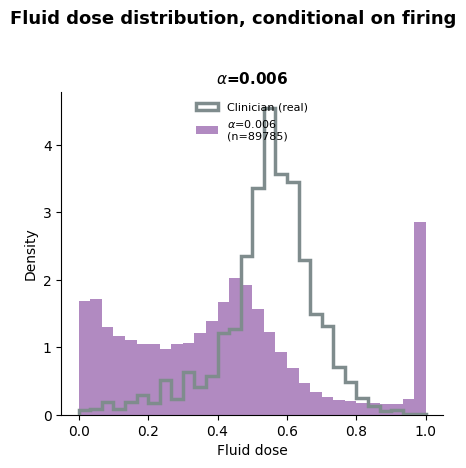

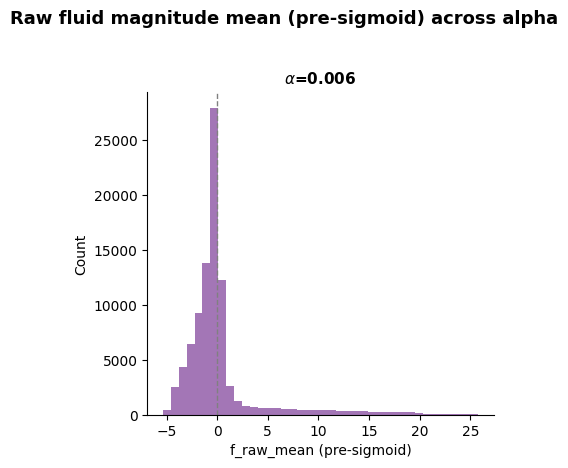

In [15]:
cql_health_score_fixed_alpha_model_dir = os.path.join(cql_model_dir, "health_score_change_only", "fixed_alpha_std_fix5")
cql_health_score_fixed_alpha_model_dirs = eval_cql.get_model_dirs(cql_health_score_fixed_alpha_model_dir)

cql_health_score_fixed_alpha_models = []
for model_dir in cql_health_score_fixed_alpha_model_dirs:
    # load health score sarsa model
    health_score_actor, health_score_critic, health_score_config_manager, health_score_hyperparams = \
        etm.load_actor_and_critic(
            model_dir=model_dir, model_type = 'cql', state_dim=state_dim,
        )
    cql_health_score_fixed_alpha_models.append((health_score_actor, health_score_critic, health_score_config_manager, health_score_hyperparams))

# Build alpha -> model dicts for each CQL sweep, keyed by each model's own cql_alpha hyperparameter.
# CQL tuples are (actor, critic, config_manager, hyperparams) -> hyperparams at index 3
cql_health_score_by_alpha = {m[3]['cql_alpha']: m for m in cql_health_score_fixed_alpha_models}

print("Health-score alphas found:", sorted(cql_health_score_by_alpha.keys()))

clinician_actions_val = processors['val'].rl_dataset["actions"]

fig = dose_hist.plot_dose_histograms(
    cql_health_score_by_alpha,
    alphas_to_show=[0.006],
    processor=processors['val'],
    clinician_actions=clinician_actions_val,
    dim=0, dim_name="Fluid",
    get_actor_actions_fn=action_dist.get_actor_actions,
    save_path=os.path.join(cql_model_dir, "dose_histogram_fluid_by_alpha.png"),
)

fig = raw_params.plot_raw_params_by_alpha(
    cql_health_score_by_alpha,
    alphas_to_show=[0.006],
    processor=processors['val'],
    save_path=os.path.join(cql_model_dir, "fluid_raw_params_by_alpha.png"),
)

In [16]:
f_raw_mean, f_p = spike_diag.get_raw_params_and_gate(
    cql_health_score_fixed_alpha_models[0],  # adjust to however you're indexing the single model you loaded
    processors['test'],
)
clinician_actions_test = processors['test'].rl_dataset["actions"]

spike_mask = spike_diag.diagnose_fluid_spike(
    f_raw_mean, f_p, test_health_score, clinician_actions_test,
    spike_threshold=5.0,
)

Spike threshold: f_raw_mean > 5.0
Fraction of states in spike: 0.0678  (7907 of 116662)

--- Health score (severity) ---
  Spike states:     mean=56.91, std=24.49, p10=18.12, p90=81.78
  Non-spike states: mean=78.89, std=14.88, p10=66.17, p90=90.88

--- Gate confidence (f_p) ---
  Spike states:     mean=0.991400, min=0.000000, max=1.000000
  Non-spike states: mean=0.984645, min=0.000000, max=1.000000
  Spike states within 1e-4 of f_p=1.0: 0.9914
  Spike states within 1e-6 of f_p=1.0: 0.9914

--- Real clinician fluid dose, at these same states ---
  Spike states:     mean=0.5683, median=0.5880
  Non-spike states: mean=0.4843, median=0.5455

--- Real clinician VASO dose, at these same states (checking for cross-drug pattern) ---
  Spike states:     mean=0.0959, fire_rate=0.3220
  Non-spike states: mean=0.0209, fire_rate=0.0770


Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/fluid_two_population_by_vaso.png


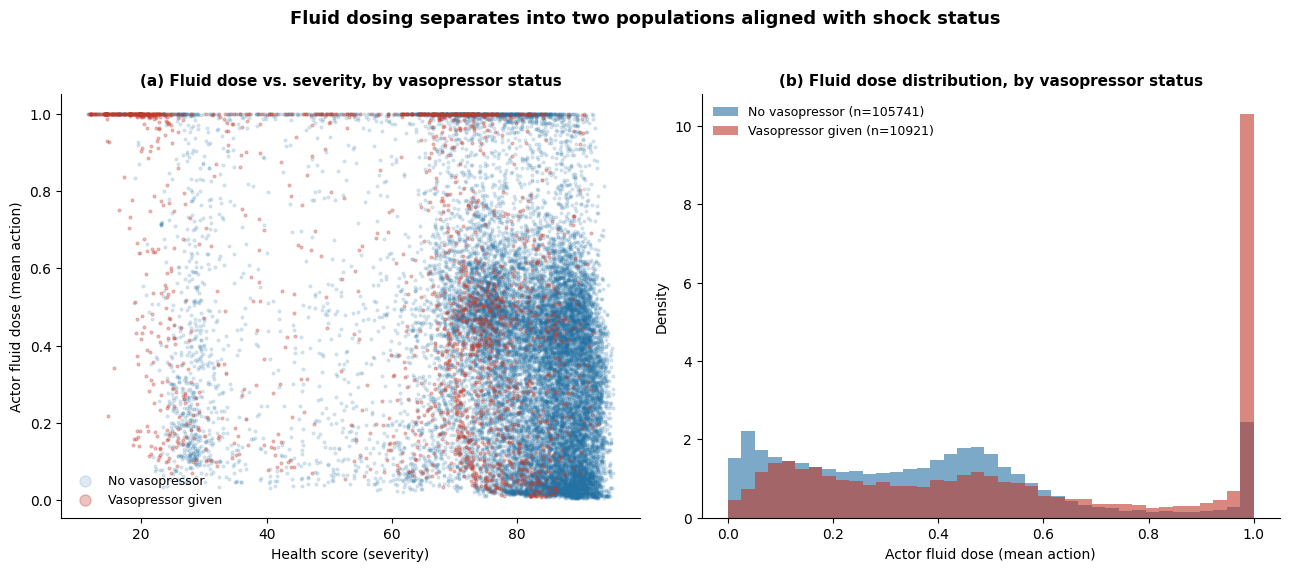

In [17]:
clinician_actions_test = processors['test'].rl_dataset["actions"]
fig = fluid_pop.plot_fluid_spike_by_severity_and_vaso(
    f_raw_mean, test_health_score, clinician_actions_test,
    save_path=os.path.join(cql_model_dir, "fluid_two_population_by_vaso.png"),
)

Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/fluid_dose_severity_heatmaps_normalized.png

Fraction of ALL states with dose>0.9: 0.1002
Fraction of states with dose>0.9 that are ALSO (health_score>70 AND no vaso): 0.4329
  (i.e. this fraction of the high-dose spike is NOT explained by sickness+vaso)
For comparison, (health_score>70 AND no vaso) as a fraction of ALL states: 0.7837
  (if the two numbers above are similar, the spike is NOT concentrated away from this group -- i.e. sickness/vaso does NOT explain the spike)


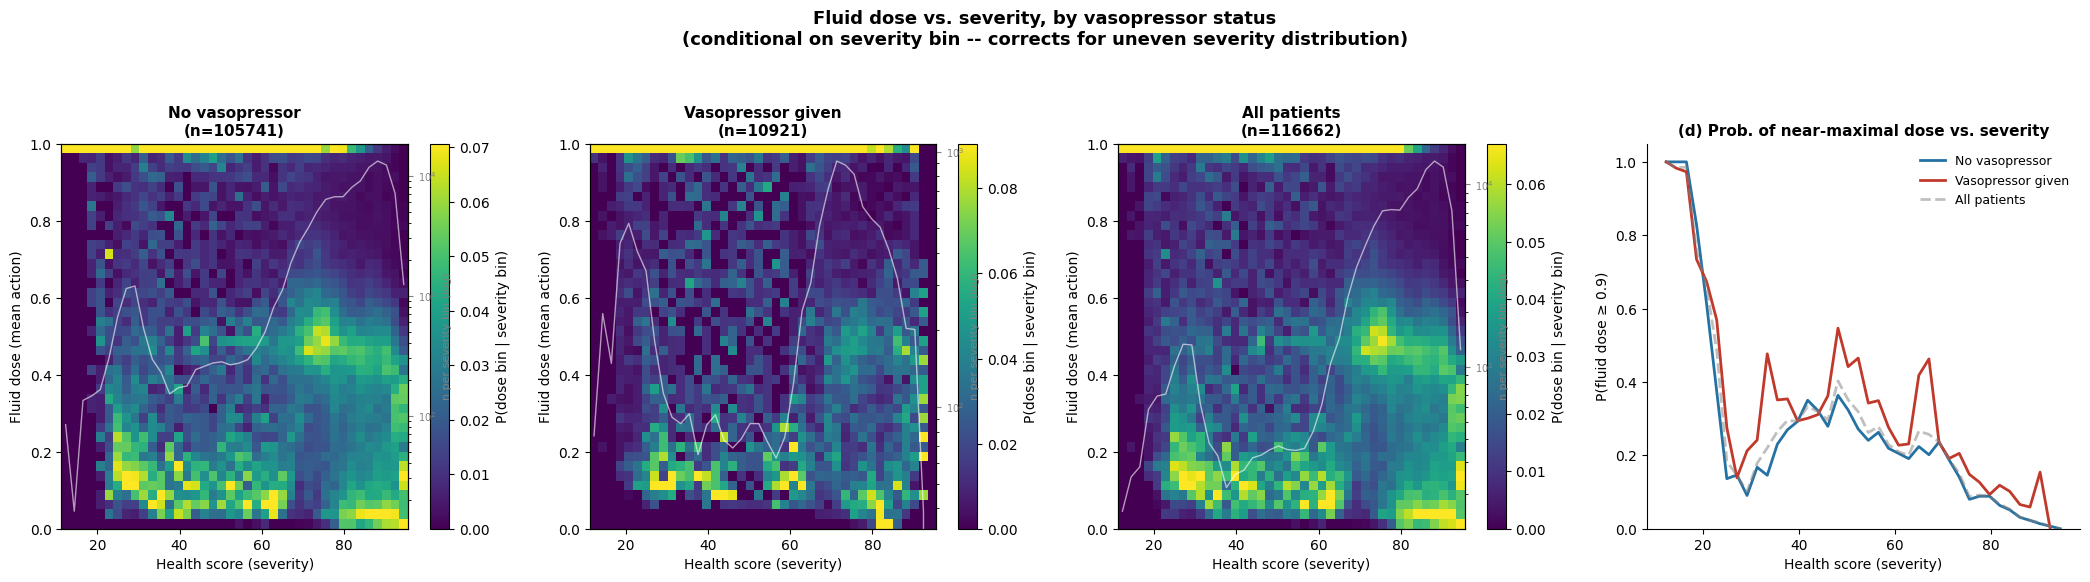

In [19]:
clinician_actions_test = processors['test'].rl_dataset["actions"]
fig = heatmap_diag.plot_fluid_dose_severity_heatmaps(
    f_raw_mean, test_health_score, clinician_actions_test,
    normalize="severity_bin",
    save_path=os.path.join(cql_model_dir, "fluid_dose_severity_heatmaps_normalized.png"),
)

## terminal models

=== alpha=0.0 ===


    own-critic Q IQR (real clinician actions): 3.4619
    SARSA seed 1 Q IQR (real clinician actions): 3.4019
    SARSA seed 2 Q IQR (real clinician actions): 3.4149
    SARSA seed 3 Q IQR (real clinician actions): 3.4782
    SARSA seed 4 Q IQR (real clinician actions): 3.5057
    SARSA seed 5 Q IQR (real clinician actions): 3.5000
  own-critic advantage:   raw=0.2745, normalized=0.0793
  SARSA-critic advantage: raw mean=0.2798, normalized mean=0.0809 (normalized per-seed=[0.0829 0.0929 0.0698 0.0855 0.0736])
  occupancy support of chosen actions: 83.1%
  done in 6.1s

=== alpha=0.0001 ===
    own-critic Q IQR (real clinician actions): 3.4603
    SARSA seed 1 Q IQR (real clinician actions): 3.4019
    SARSA seed 2 Q IQR (real clinician actions): 3.4149
    SARSA seed 3 Q IQR (real clinician actions): 3.4782
    SARSA seed 4 Q IQR (real clinician actions): 3.5057
    SARSA seed 5 Q IQR (real clinician actions): 3.5000
  own-critic advantage:   raw=0.2701, normalized=0.0781
  SARSA-criti

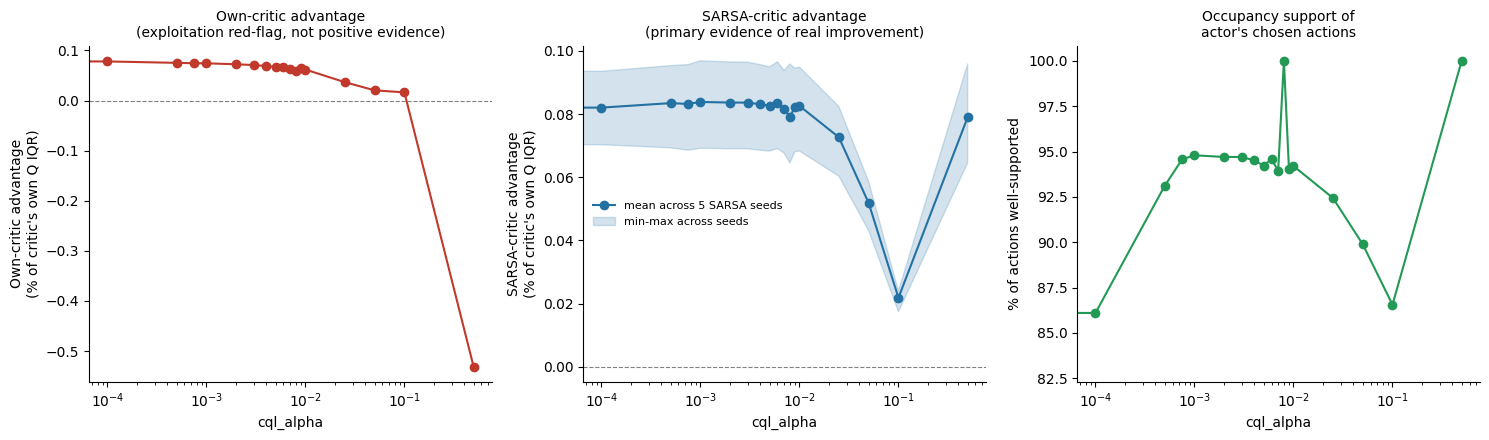

In [38]:
save_path = os.path.join(cql_model_dir, "cql_alpha_sweep_terminal_n_severity_bins_100.png")    


# --- Health-score reward: CQL alpha sweep vs. all 5 health-score SARSA seeds ---
results_terminal, fig_terminal = eval_cql.run_alpha_sweep_analysis(
    cql_terminal_by_alpha,
    processors['val'],
    basic_q_terminal_models,   # the 5 health-score SARSA seeds, as independent judges
    val_health_score,
    training_actions,
    training_health_score,
    n_severity_bins = 100,
    save_path=save_path,
)

Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/cql_alpha_sweep_combined_terminal_n_severity_bins_100.png


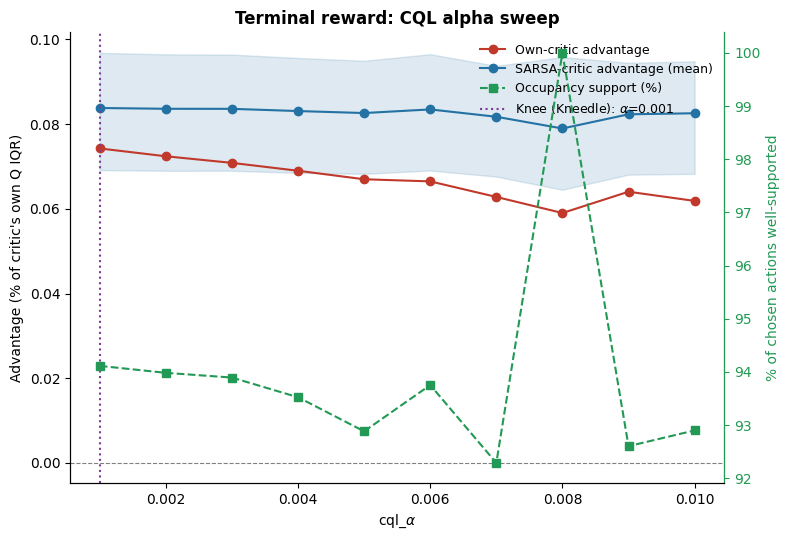

In [17]:
save_path = os.path.join(cql_model_dir, "cql_alpha_sweep_combined_terminal_n_severity_bins_100.png")  

fig = eval_cql.plot_combined_alpha_sweep(
    results_terminal,
    normalized=True,
    title="Terminal reward: CQL alpha sweep",
    save_path=save_path,
)

alpha=0.001: fluid[rate=10.9%, mean=0.1081, nonzero_mean=0.9903]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.002: fluid[rate=12.3%, mean=0.1127, nonzero_mean=0.9183]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.003: fluid[rate=11.4%, mean=0.1139, nonzero_mean=0.9995]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.004: fluid[rate=12.0%, mean=0.1199, nonzero_mean=0.9956]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.005: fluid[rate=13.5%, mean=0.1347, nonzero_mean=0.9957]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.006: fluid[rate=11.8%, mean=0.1178, nonzero_mean=0.9978]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.007: fluid[rate=16.5%, mean=0.1510, nonzero_mean=0.9155]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.008: fluid[rate=0.0%, mean=0.0000, nonzero_mean=nan]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.009: fluid[rate=14.1%, mean=0.1409, nonzero_mean=0.9970]  vaso[rate=0.0%, mean=0.0000, nonze

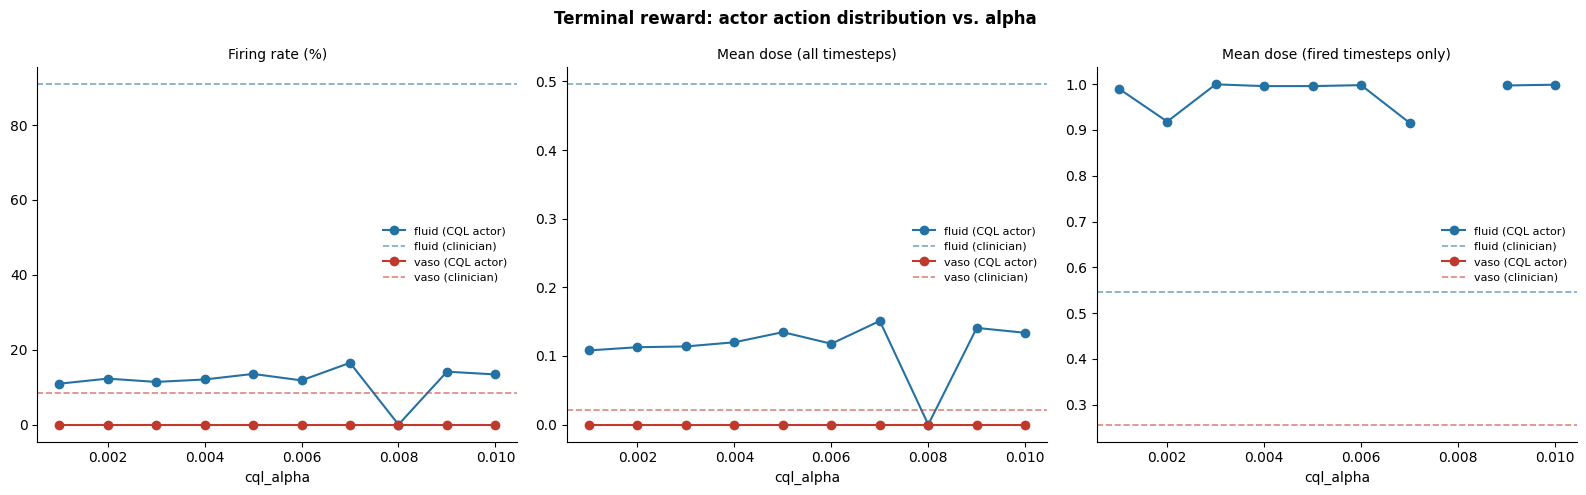

In [31]:
clinician_baseline_val = clin_baseline.compute_clinician_baseline(processors['val'].rl_dataset["actions"])

results_actions_terminal, fig_actions_terminal = action_dist.run_action_distribution_sweep(
    cql_terminal_by_alpha,
    processors['val'],
    clinician_baseline=clinician_baseline_val,
    title="Terminal reward: actor action distribution vs. alpha",
    save_path=os.path.join(cql_model_dir, "cql_alpha_sweep_actions_terminal.png"),
)

alpha=0.001: fluid[rate=30.3%, mean=0.2437, nonzero_mean=0.8053]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.002: fluid[rate=56.3%, mean=0.3414, nonzero_mean=0.6069]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.003: fluid[rate=77.5%, mean=0.4594, nonzero_mean=0.5930]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.004: fluid[rate=87.2%, mean=0.4952, nonzero_mean=0.5676]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.005: fluid[rate=94.8%, mean=0.4810, nonzero_mean=0.5077]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.006: fluid[rate=97.2%, mean=0.4264, nonzero_mean=0.4387]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.007: fluid[rate=97.1%, mean=0.4561, nonzero_mean=0.4698]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.008: fluid[rate=99.1%, mean=0.4676, nonzero_mean=0.4717]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
alpha=0.009: fluid[rate=99.8%, mean=0.4724, nonzero_mean=0.4736]  vaso[rate=0.0%, mean=0.0000, n

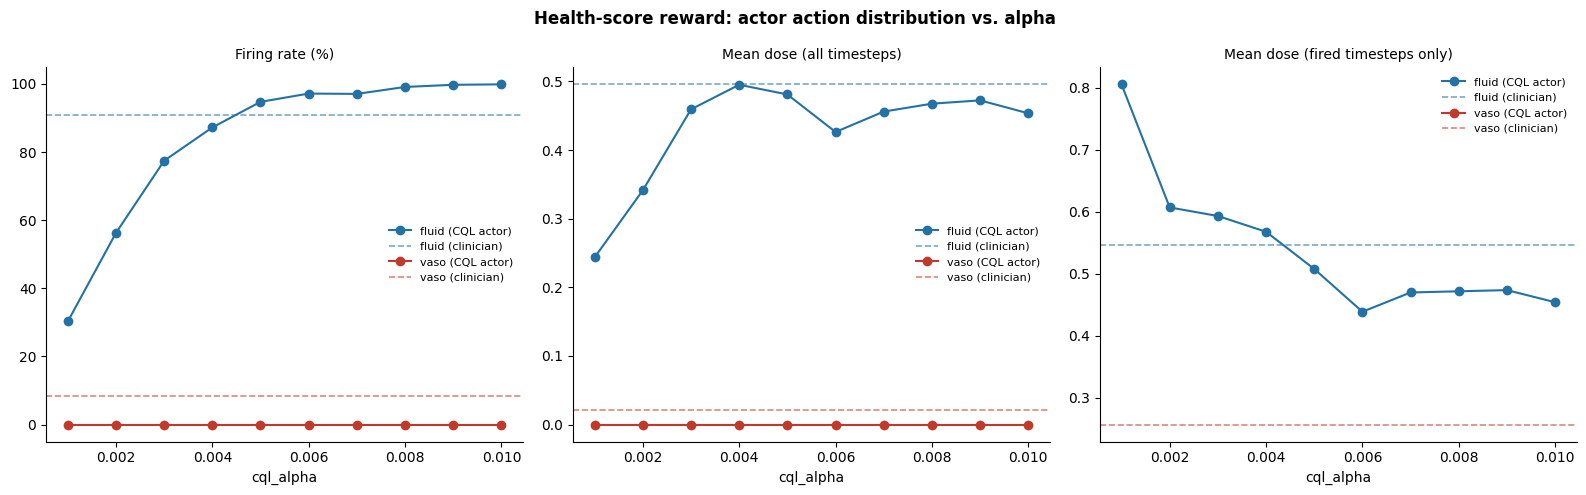

In [32]:
results_actions_health_score, fig_actions_health_score = action_dist.run_action_distribution_sweep(
    cql_health_score_by_alpha,
    processors['val'],
    clinician_baseline=clinician_baseline_val,
    title="Health-score reward: actor action distribution vs. alpha",
    save_path=os.path.join(cql_model_dir, "cql_alpha_sweep_actions_health_score.png"),
)

# final 5 seed models with fixed cql alpha

In [20]:
cql_model_dir

'/home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset'

In [21]:
cql_terminal_fixed_alpha_model_dir = os.path.join(cql_model_dir, "terminal_only", "fixed_alpha")
cql_terminal_fixed_alpha_model_dirs = eval_cql.get_model_dirs(cql_terminal_fixed_alpha_model_dir)

cql_terminal_fixed_alpha_models = []
for model_dir in cql_terminal_fixed_alpha_model_dirs:
    # load terminal sarsa model
    terminal_actor, terminal_critic, terminal_config_manager, terminal_hyperparams = \
        etm.load_actor_and_critic(
            model_dir=model_dir, model_type = 'cql', state_dim=state_dim,
        )
    cql_terminal_fixed_alpha_models.append((terminal_actor, terminal_critic, terminal_config_manager, terminal_hyperparams))

Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/terminal_only/fixed_alpha/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260906_215328/unknown_cx3-20-6_20260906-220822_0ce993d0
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/terminal_only/fixed_alpha/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260906_215328/unknown_cx3-20-6_20260906-223125_f7922617
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/terminal_only/fixed_alpha/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260906_215328/unknown_cx3-20-6_20260906-215444_c0ab74de
Found model directory: /home/ja

In [23]:
cql_health_score_fixed_alpha_model_dir = os.path.join(cql_model_dir, "health_score_change_only", "fixed_alpha")
cql_health_score_fixed_alpha_model_dirs = eval_cql.get_model_dirs(cql_health_score_fixed_alpha_model_dir)

cql_health_score_fixed_alpha_models = []
for model_dir in cql_health_score_fixed_alpha_model_dirs:
    # load health score sarsa model
    health_score_actor, health_score_critic, health_score_config_manager, health_score_hyperparams = \
        etm.load_actor_and_critic(
            model_dir=model_dir, model_type = 'cql', state_dim=state_dim,
        )
    cql_health_score_fixed_alpha_models.append((health_score_actor, health_score_critic, health_score_config_manager, health_score_hyperparams))

Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260907_095831/unknown_cx3-20-6_20260907-110857_6a599bed
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260907_095831/unknown_cx3-20-6_20260907-095956_924ca060
Found model directory: /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/health_score_change_only/fixed_alpha/choc_cql_with_logprobs_intake-vis_best_hyperparameters_fixed_cql_alpha_20260907_095831/unknown_cx3-20-6_20260907-101849_70f2dd3

seed 1/5: fluid[rate=93.2%, mean=0.4356, nonzero_mean=0.4677]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
seed 2/5: fluid[rate=93.3%, mean=0.4161, nonzero_mean=0.4458]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
seed 3/5: fluid[rate=92.5%, mean=0.3793, nonzero_mean=0.4102]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
seed 4/5: fluid[rate=95.4%, mean=0.3856, nonzero_mean=0.4043]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
seed 5/5: fluid[rate=98.7%, mean=0.4178, nonzero_mean=0.4234]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/stage3_actions_health_score.png


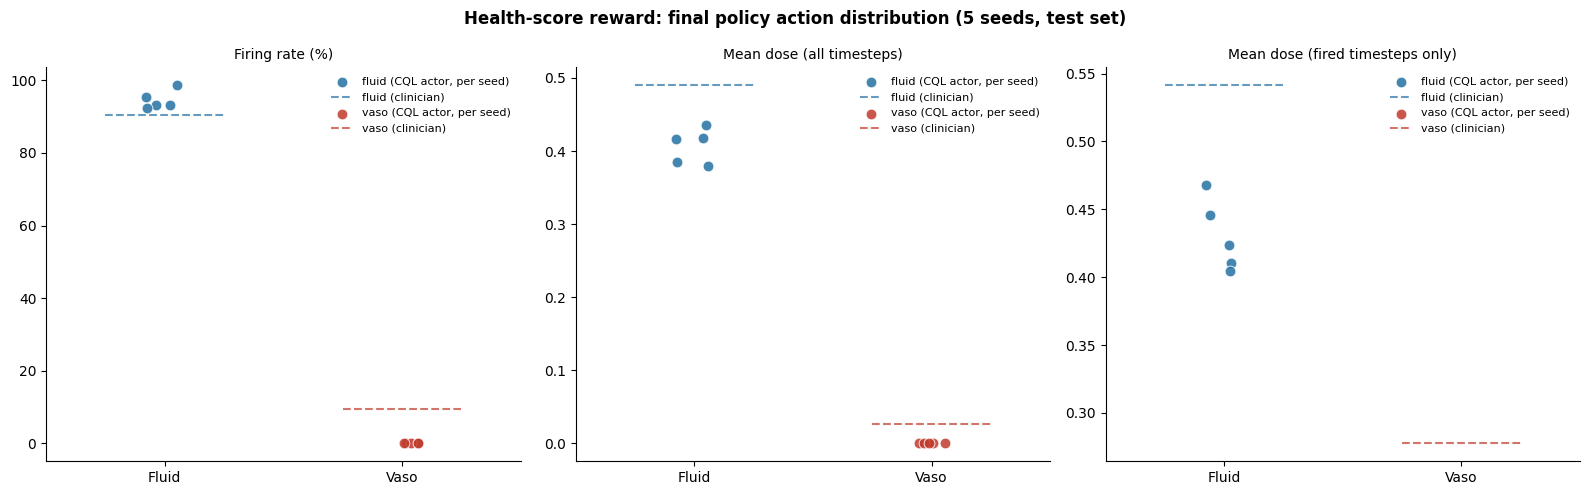

In [24]:
clinician_baseline_test = clin_baseline.compute_clinician_baseline(processors['test'].rl_dataset["actions"])

stats_health_score, fig_health_score = action_dist.run_action_distribution_stage3(
    cql_health_score_fixed_alpha_models,
    processors['test'],
    clinician_baseline=clinician_baseline_test,
    title="Health-score reward: final policy action distribution (5 seeds, test set)",
    save_path=os.path.join(cql_model_dir, "stage3_actions_health_score.png"),
)

In [26]:
all_f_std, all_v_std = std_check.check_std_floor_across_seeds(
    cql_health_score_fixed_alpha_models,
    processors['val'],
)

Floor std (exp(log_std_min=-2.0)) = 0.1353
Ceiling std (exp(log_std_max=1.0)) = 2.7183

seed 1: f_std [mean=0.1353, min=0.1353, max=0.1353, %_at_floor=100.0%]  v_std [mean=0.2166, min=0.1353, max=0.2815, %_at_floor=3.0%]
seed 2: f_std [mean=0.1353, min=0.1353, max=0.1353, %_at_floor=100.0%]  v_std [mean=0.2014, min=0.1353, max=0.2508, %_at_floor=1.1%]
seed 3: f_std [mean=0.1353, min=0.1353, max=0.1353, %_at_floor=100.0%]  v_std [mean=0.2637, min=0.1353, max=0.3252, %_at_floor=0.1%]
seed 4: f_std [mean=0.1353, min=0.1353, max=0.1353, %_at_floor=100.0%]  v_std [mean=0.1692, min=0.1353, max=0.2318, %_at_floor=23.9%]
seed 5: f_std [mean=0.1353, min=0.1353, max=0.1353, %_at_floor=100.0%]  v_std [mean=0.2904, min=0.1353, max=0.4013, %_at_floor=0.1%]

Across all 5 seeds combined: f_std mean=0.1353 (100.0% at floor), v_std mean=0.2283 (5.6% at floor)


seed 1/5: fluid[rate=19.9%, mean=0.1784, nonzero_mean=0.8979]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
seed 2/5: fluid[rate=15.6%, mean=0.1441, nonzero_mean=0.9243]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
seed 3/5: fluid[rate=13.8%, mean=0.1362, nonzero_mean=0.9902]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
seed 4/5: fluid[rate=15.0%, mean=0.1409, nonzero_mean=0.9381]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
seed 5/5: fluid[rate=12.0%, mean=0.1153, nonzero_mean=0.9619]  vaso[rate=0.0%, mean=0.0000, nonzero_mean=nan]
Saved to /home/jake/Documents/AI_Clinician/models/rl_models/choc/cql_with_logprobs/split_0/sepsis/intake-vis/picu_patients_health_score_from_picu_dataset/stage3_actions_terminal.png


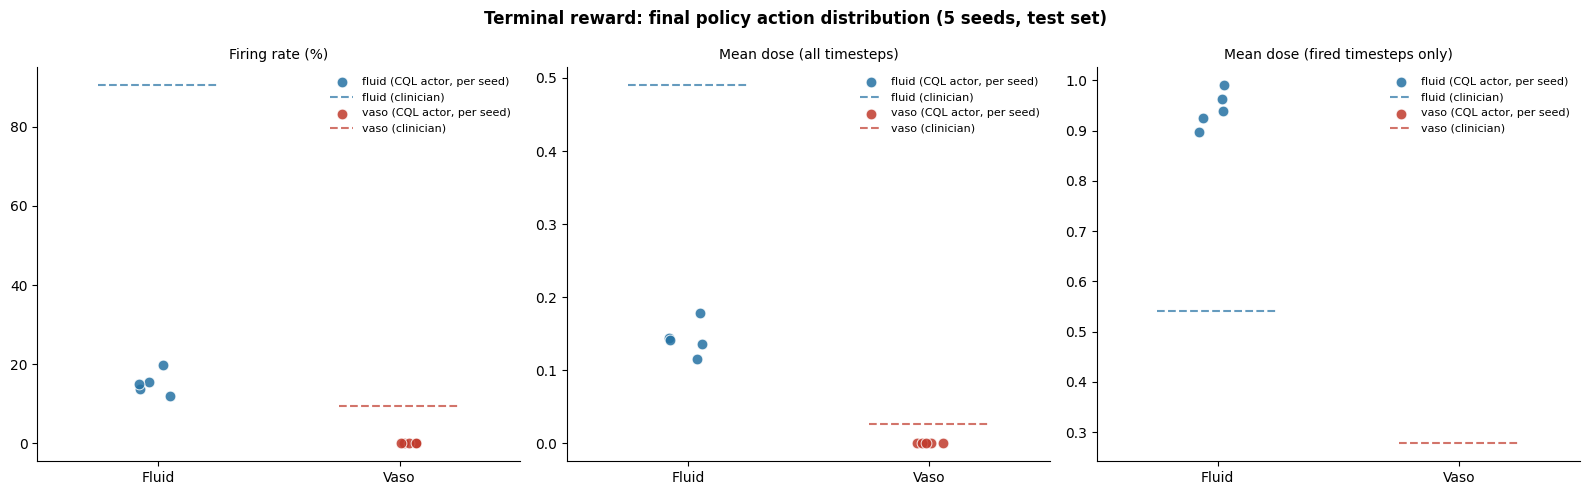

In [39]:
stats_terminal, fig_terminal = action_dist.run_action_distribution_stage3(
    cql_terminal_fixed_alpha_models,
    processors['test'],
    clinician_baseline=clinician_baseline_test,
    title="Terminal reward: final policy action distribution (5 seeds, test set)",
    save_path=os.path.join(cql_model_dir, "stage3_actions_terminal.png"),
)

# reward by vaso 

Matched effect estimate (no-vaso minus vaso, weighted by n_vaso per bin): 0.0440
Total vaso-given timesteps contributing to estimate: 10921
  bin center hs=34.0: vaso mean=0.000447 (n=3660), no_vaso mean=0.095069 (n=8007)
  bin center hs=68.1: vaso mean=0.013176 (n=2498), no_vaso mean=0.016489 (n=9168)
  bin center hs=73.9: vaso mean=0.078589 (n=1616), no_vaso mean=0.082335 (n=10050)
  bin center hs=77.5: vaso mean=-0.013044 (n=1041), no_vaso mean=0.044067 (n=10625)
  bin center hs=80.8: vaso mean=0.041779 (n=793), no_vaso mean=0.066261 (n=10873)
  bin center hs=83.7: vaso mean=0.063762 (n=539), no_vaso mean=0.047470 (n=11127)
  bin center hs=86.1: vaso mean=-0.134604 (n=326), no_vaso mean=0.029251 (n=11340)
  bin center hs=88.0: vaso mean=-0.038649 (n=172), no_vaso mean=-0.012884 (n=11494)
  bin center hs=89.8: vaso mean=-0.004516 (n=203), no_vaso mean=-0.023176 (n=11463)
  bin center hs=92.1: vaso mean=0.015111 (n=73), no_vaso mean=-0.037300 (n=11594)
Saved to /home/jake/Documents/AI

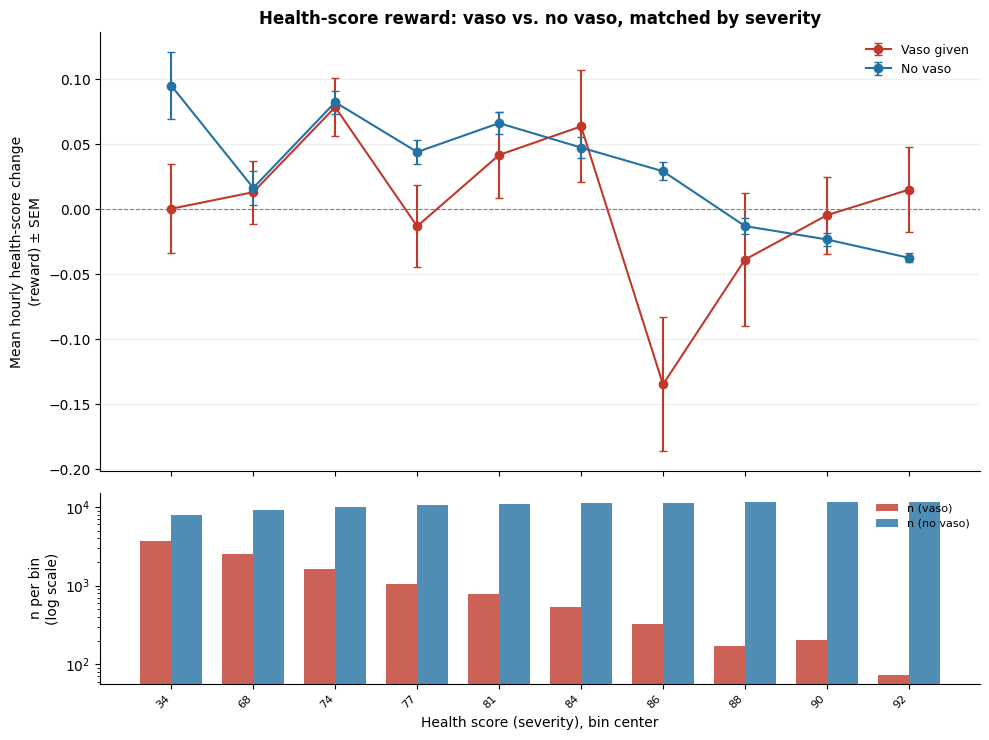

In [65]:
test_health_score = processors['test'].dynamic_deephit_predictions["health_score"]
# remove values at indices processors['test'].dynamic_deephit_predictions['index_ptr'][1:] - 1
indices_to_remove = processors['test'].dynamic_deephit_predictions['index_ptr'][1:] - 1
test_health_score = np.delete(test_health_score, indices_to_remove)

rewards = processors['test'].rl_dataset["rewards"]
actions = processors['test'].rl_dataset["actions"]

health_score = processors['test'].dynamic_deephit_predictions['health_score'] 

results = vaso_match.compare_reward_by_vaso(
    rewards, actions, test_health_score, n_severity_bins=10
)

effect, total_n_vaso = vaso_match.matched_effect_estimate(results)
print(f"Matched effect estimate (no-vaso minus vaso, weighted by n_vaso per bin): {effect:.4f}")
print(f"Total vaso-given timesteps contributing to estimate: {total_n_vaso}")

for b in range(len(results["bin_center_health_score"])):
    print(f"  bin center hs={results['bin_center_health_score'][b]:.1f}: "
      f"vaso mean={results['mean_reward_vaso'][b]:.6f} (n={results['n_vaso'][b]}), "
      f"no_vaso mean={results['mean_reward_no_vaso'][b]:.6f} (n={results['n_no_vaso'][b]})")

fig = vaso_match.plot_reward_by_vaso(
    results,
    title="Health-score reward: vaso vs. no vaso, matched by severity",
    save_path=os.path.join(cql_model_dir, "reward_by_vaso_matched.png"),
)

In [1]:
val_health_score = processors['val'].dynamic_deephit_predictions["health_score"]
# remove values at indices processors['val'].dynamic_deephit_predictions['index_ptr'][1:] - 1
indices_to_remove = processors['val'].dynamic_deephit_predictions['index_ptr'][1:] - 1
val_health_score = np.delete(val_health_score, indices_to_remove)

rewards = processors['val'].rl_dataset["rewards"]
actions = processors['val'].rl_dataset["actions"]

health_score = processors['val'].dynamic_deephit_predictions['health_score'] 

results = vaso_match.compare_reward_by_vaso(
    rewards, actions, val_health_score, n_severity_bins=10
)

effect, total_n_vaso = vaso_match.matched_effect_estimate(results)
print(f"Matched effect estimate (no-vaso minus vaso, weighted by n_vaso per bin): {effect:.4f}")
print(f"Total vaso-given timesteps contributing to estimate: {total_n_vaso}")

for b in range(len(results["bin_center_health_score"])):
    print(f"  bin center hs={results['bin_center_health_score'][b]:.1f}: "
      f"vaso mean={results['mean_reward_vaso'][b]:.6f} (n={results['n_vaso'][b]}), "
      f"no_vaso mean={results['mean_reward_no_vaso'][b]:.6f} (n={results['n_no_vaso'][b]})")

fig = vaso_match.plot_reward_by_vaso(
    results,
    title="Health-score reward: vaso vs. no vaso, matched by severity",
    save_path=os.path.join(cql_model_dir, "reward_by_vaso_matched_VALIDATION.png"),
)

NameError: name 'processors' is not defined